In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = sns.load_dataset("titanic")

In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(891, 15)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [7]:

df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')


In [9]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


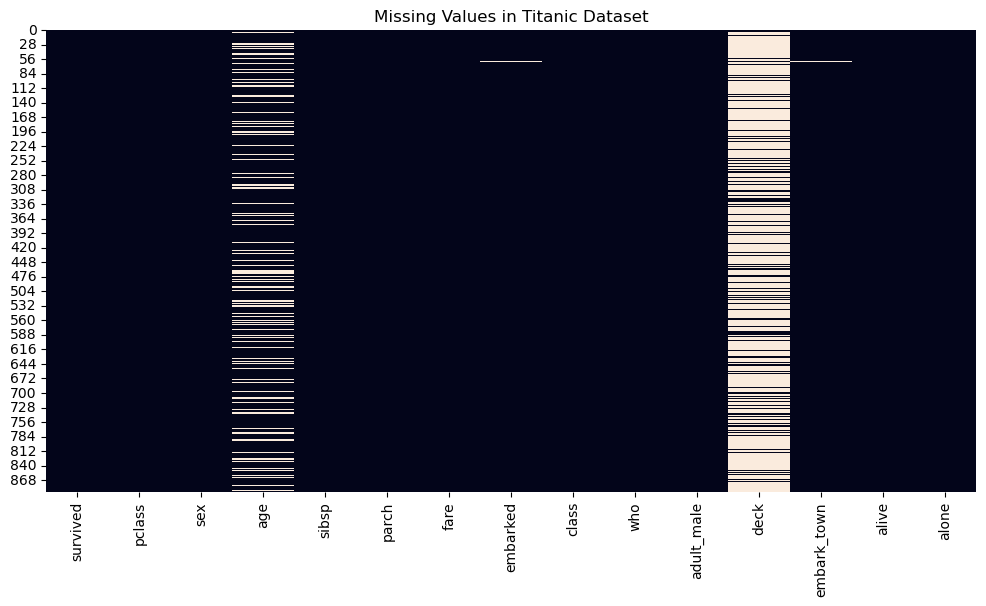

In [10]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [11]:
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

In [12]:
df = df.drop(columns=["deck"])

In [13]:
df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

In [14]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [15]:
df["embark_town"] = df["embark_town"].fillna(
    df["embark_town"].mode()[0]
)

In [16]:
print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [17]:
print("Duplicate Records:")
print(df.duplicated().sum())

Duplicate Records:
118


In [18]:

print("Data Types:")
print(df.dtypes)

Data Types:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
embark_town      object
alive            object
alone              bool
dtype: object


In [19]:
print("Survival Rate by Gender:")

gender_survival = df.groupby("sex")["survived"].mean()

print(gender_survival)

Survival Rate by Gender:
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


In [20]:
print("Survival Rate by Passenger Class:")

class_survival = df.groupby("pclass")["survived"].agg(
    ["mean", "count"]
)

print(class_survival.round(2))

Survival Rate by Passenger Class:
        mean  count
pclass             
1       0.63    216
2       0.47    184
3       0.24    491


In [21]:
df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"]
)

In [22]:
print("Survival Rate by Age Group:")

age_survival = df.groupby(
    "age_band", observed=True
)["survived"].mean()

print(age_survival.round(2))

Survival Rate by Age Group:
age_band
Child          0.58
Teen           0.43
Adult          0.36
Middle-aged    0.39
Senior         0.23
Name: survived, dtype: float64


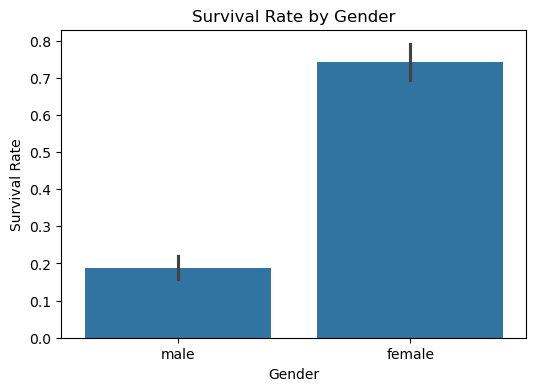

In [23]:
plt.figure(figsize=(6, 4))

sns.barplot(data=df, x="sex", y="survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

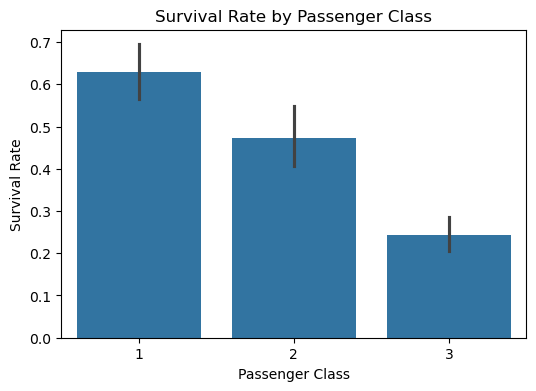

In [24]:
plt.figure(figsize=(6, 4))

sns.barplot(data=df, x="pclass", y="survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

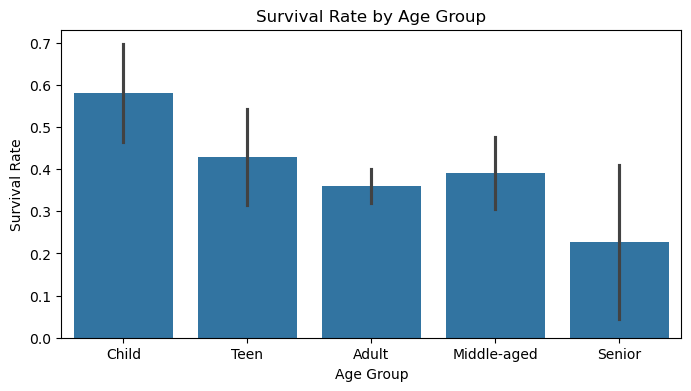

In [25]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=df,
    x="age_band",
    y="survived"
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

plt.show()

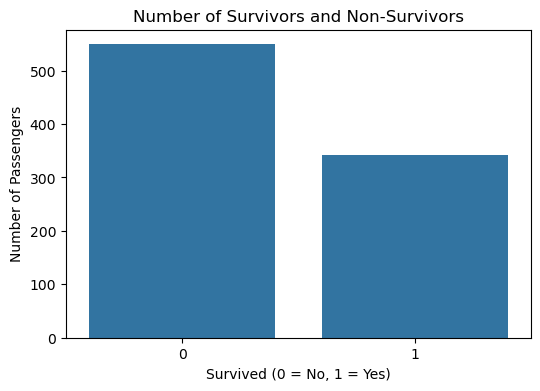

In [26]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="survived")

plt.title("Number of Survivors and Non-Survivors")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

# Titanic Exploratory Data Analysis (EDA)

## Project Conclusion

In this project, I performed Exploratory Data Analysis on the Titanic dataset using Python.

I used Pandas, NumPy, Matplotlib and Seaborn to inspect, clean and analyze the data.

### Key Findings

1. **Gender Analysis:** Female passengers had a higher survival rate than male passengers.
2. **Passenger Class Analysis:** First-class passengers had a higher survival rate (63%) compared with second-class (47%) and third-class passengers (24%).
3. **Age Analysis:** Children had a survival rate of 58%, while senior passengers had a survival rate of 23%.

### Data Cleaning

- Handled missing age values using median.
- Filled missing embarked and embark_town values using mode.
- Removed the deck column because it contained many missing values.
- Checked duplicate records.

### Final Conclusion

This project helped me understand data cleaning, data analysis, grouping, aggregation and data visualization using Python.